In [95]:
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import numpy as np
from scipy import stats

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
%load_ext autoreload
%autoreload 2

###can also use dir() to check what is in function and that new params have been loaded

import os
import glob


#desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
plot_path="../output/plots"
mypath = plot_path

import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Import Data

In [96]:
EMdata = {}

#root = 'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/EM/classicFix/data/'
#root = 'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/EM/'
root = 'E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/EM/'

folder = root+'DD0075_E5/tables/'
file = 'D1_binary - Local Diameter.csv'
EMdata['branch1'] = {'path':folder+file}
EMdata['branch1']['ex_factor'] = 1
EMdata['branch1']['res'] = 0.01 #10nm voxel

file = 'D2_binary - Local Diameter.csv'
EMdata['branch2'] = {'path':folder+file}
EMdata['branch2']['ex_factor'] = 1
EMdata['branch2']['res'] = 0.01 #10nm voxel

file = 'D4_binary - Local Diameter.csv'
EMdata['branch4'] = {'path':folder+file}
EMdata['branch4']['ex_factor'] = 1
EMdata['branch4']['res'] = 0.01 #10nm voxel

file = 'D5_binary - Local Diameter.csv'
EMdata['branch5'] = {'path':folder+file}
EMdata['branch5']['ex_factor'] = 1
EMdata['branch5']['res'] = 0.01 #10nm voxel


# # #03 replaced area missing due to bubble in EM stack with binary segemted above
# # #06 corrected skeleton
    
# # #07 corrected skeleton
# # #09 replaced area missing due to bubble in EM stack with binary segment 
    
folder = root+'DD0075_E5/tables/'
file = '03 - Local Diameter.csv'
EMdata['branch3'] = {'path':folder+file}
EMdata['branch3']['ex_factor'] = 1
EMdata['branch3']['res'] = 0.01 

EMdata['branch6'] = {'path':folder+'06 - Local Diameter.csv'}
EMdata['branch6']['ex_factor'] = 1
EMdata['branch6']['res'] = 0.01 

EMdata['branch7'] = {'path':folder+'07 - Local Diameter.csv'}
EMdata['branch7']['ex_factor'] = 1
EMdata['branch7']['res'] = 0.01 

EMdata['branch8'] = {'path':folder+'08 - Local Diameter.csv'}
EMdata['branch8']['ex_factor'] = 1
EMdata['branch8']['res'] = 0.01

EMdata['branch9'] = {'path':folder+'09 - Local Diameter.csv'}
EMdata['branch9']['ex_factor'] = 1
EMdata['branch9']['res'] = 0.01


folder = root+'1922_DistalMolLayer/tables/'
file = 'object02 - Local Diameter.csv'
EMdata['branch12'] = {'path':folder+file}
EMdata['branch12']['ex_factor'] = 1
EMdata['branch12']['res'] = 0.01 

file = 'object03 - Local Diameter.csv'
EMdata['branch13'] = {'path':folder+file}
EMdata['branch13']['ex_factor'] = 1
EMdata['branch13']['res'] = 0.01 

file = 'object04 - Local Diameter.csv'
EMdata['branch14'] = {'path':folder+file}
EMdata['branch14']['ex_factor'] = 1
EMdata['branch14']['res'] = 0.01 

file = 'object07 - Local Diameter.csv'
EMdata['branch17'] = {'path':folder+file}
EMdata['branch17']['ex_factor'] = 1
EMdata['branch17']['res'] = 0.01 #50nm voxel

# file = 'object092 - Local Diameter.csv' ## but jumpy realign From Michael???
# EMdata['branch19'] = {'path':folder+file}
# EMdata['branch19']['ex_factor'] = 1
# EMdata['branch19']['res'] = 0.01 

file = 'object10 - Local Diameter.csv'
EMdata['branch20'] = {'path':folder+file}
EMdata['branch20']['ex_factor'] = 1
EMdata['branch20']['res'] = 0.01 

file = 'object11 - Local Diameter.csv'
EMdata['branch21'] = {'path':folder+file}
EMdata['branch21']['ex_factor'] = 1
EMdata['branch21']['res'] = 0.01 

file = 'object12 - Local Diameter.csv'
EMdata['branch22'] = {'path':folder+file}
EMdata['branch22']['ex_factor'] = 1
EMdata['branch22']['res'] = 0.01 

file = 'object15 - Local Diameter.csv'
EMdata['branch25'] = {'path':folder+file}
EMdata['branch25']['ex_factor'] = 1
EMdata['branch25']['res'] = 0.01 

In [97]:
dataSet=EMdata
for name, dendrite in tqdm(dataSet.items()):
    #print(name)
    #print(data[name]['path'])
    
    file_path = dendrite['path']#+dendrite['file']
    dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'], p=100, pdiff=1)

100%|██████████| 17/17 [00:03<00:00,  4.42it/s]


In [98]:
### add manual to the data dictionary 
# ##add manual branch5 goes below x2 threshold but sligth increase excludes it from algorythm eventhough still DSC in my opinion  
branch=EMdata['branch4']
DSC=branch['data'][120:275].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 

branch=EMdata['branch5']
DSC=branch['data'][360:700].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC)  

branch=EMdata['branch14']
DSC=branch['data'][364:450].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC)  


##maybe other DSCs in branch 17 object7 but difficult to confirm without proper registration.
del EMdata['branch17']['DSCs'][1]


In [99]:
update_DSCs(EMdata['branch4'])
update_DSCs(EMdata['branch5'])


# update_DSCs(EMdata['branch8']) # end of dendrite
update_DSCs(EMdata['branch14'])

update_DSCs(EMdata['branch17'])
# update_DSCs(EMdata['branch20'])




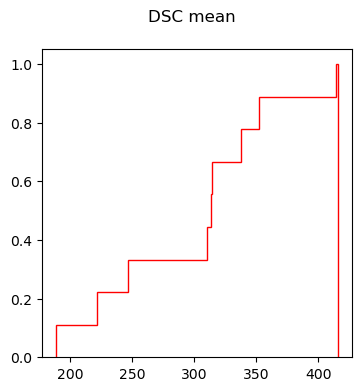

In [106]:
#select property to plot [mean, lenght]
parameter='mean'

df= summary_dsc(EMdata, parameter)

n_bins=200
fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle('DSC '+parameter)

df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='red', density=True, histtype='step', cumulative=True)
#ax.set_xlim([0,10])

fig.savefig(mypath+'/EM_DSC_diam_Cumulative.svg', bbox_inches = 'tight')

In [105]:
df.mean()

0    300.66471
dtype: float64

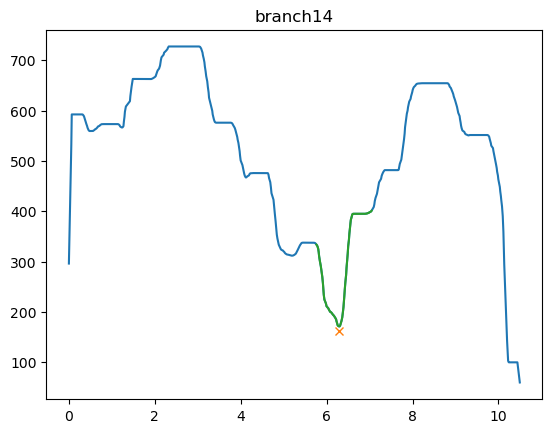

In [116]:
from plots import plot_dsc
dend_name= 'branch14'  
branchNo= 3
df=EMdata[dend_name]['data']
df=EMdata[dend_name]['DSC_properties']
fig, ax = plot_dsc(EMdata[dend_name],dend_name, corr=1)  

In [103]:
df= summary_dsc(EMdata, parameter)
#df=EMdata[dend_name]['DSCs'][0]

In [104]:
minX=np.argmin(DSC.smth)

start = np.argmin(DSC.deriv2[0:minX+DSC.index.start+-3]) #-3 DSC.index[0])
end = np.argmax(DSC.deriv2[minX+3:]) + minX+3 #+3 DSC.index[0])
#print(DSC[start])